# Self Consistency와 표본 합의

**이 노트북에서 할 일**

1. 05절 답만 받는 목록에 분류 이름 규칙 한 문장을 더하고, 같은 목록을 세 번 따로 보냅니다.
2. 세 답의 첫 줄에서 분류 이름을 꺼내 표를 세고, 절반보다 많은 표를 받은 분류를 합의로 정합니다.
3. 합의와 답 내용을 따로 확인하고, 분류 이름 규칙이 없는 목록도 세 번 보내 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 6번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

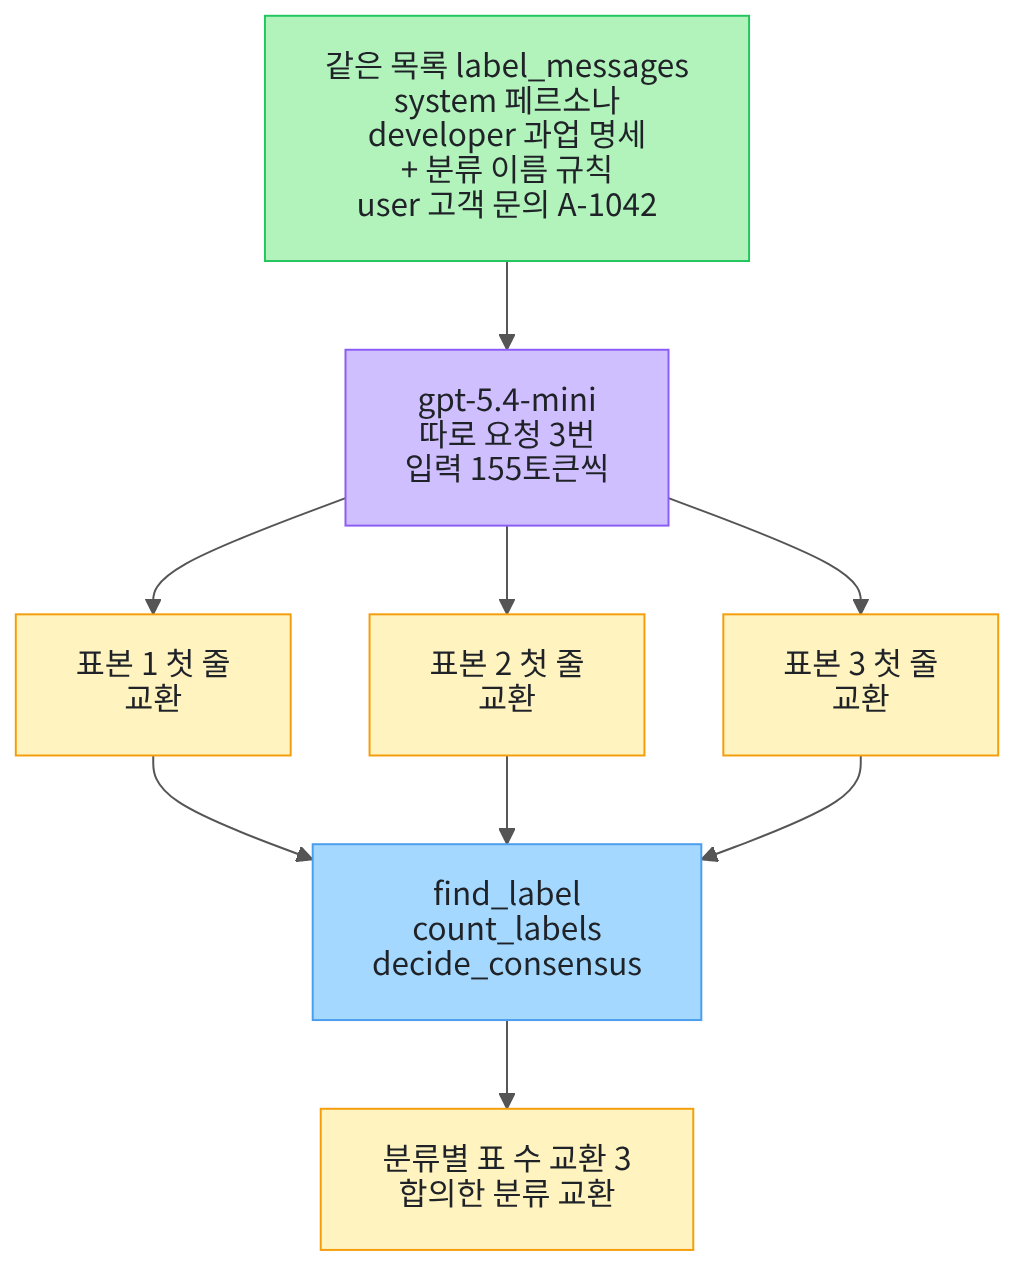

위에서 아래로 읽습니다. 맨 위 초록 상자는 분류 이름 규칙 한 문장을 더한 목록입니다.
보라 상자에서 같은 목록을 세 번 따로 보냅니다.

가운데 노란 상자 셋은 세 표본 답의 첫 줄입니다. 파란 상자는 이 노트북에서 정의하는 세 함수입니다.
맨 아래 노란 상자가 표를 센 결과와 합의한 분류이고, 9절에서 확인합니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~05절과 같은 실습 폴더와 같은 판입니다. 노트북은 앞 절 없이 새 커널에서 시작하므로 다시 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

걸린 시간을 재는 모듈 `time`(Ch 6 05절)과 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 시간을 재는 모듈과 모델 객체를 만드는 함수를 불러옵니다
import time

from langchain.chat_models import init_chat_model

01~05절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01~05절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

인자 `reasoning_effort="none"`도 01~05절과 같습니다. 05절에서는 이 설정의 세 응답 모두 추론 토큰이 0이었습니다.

## 2. 05절 답만 받는 목록 다시 만들기

05절 답만 받는 목록은 system 페르소나, developer 과업 명세, user 고객 문의 세 메시지였습니다.
과업 명세의 출력 형식은 분류·다음 행동·고객 문장을 한 줄씩 세 줄로 요청합니다.

이 절도 03·05절처럼 튜플 목록으로 만듭니다. 이 목록은 11절 값 바꿔 보기에서 다시 씁니다.

In [5]:
# 05절과 같은 페르소나 글·고객 문의·과업 명세로 답만 받는 목록을 만듭니다
persona_text = "당신은 친절한 고객 상담원입니다."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + format_text
answer_messages = [("system", persona_text), ("developer", task_text), ("user", inquiry_text)]
print("과업 명세:")
print(task_text)
print("답만 받는 목록의 메시지 수:", len(answer_messages))

과업 명세:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.
분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.
답만 받는 목록의 메시지 수: 3


**결과 읽기** — 라벨 줄 `과업 명세:` 아래 네 줄은 05절 답만 받는 목록과 같은 과업 명세입니다.
마지막 줄은 `답만 받는 목록의 메시지 수: 3`입니다.

## 3. 분류 이름 규칙 한 문장 더하기

같은 답만 받는 목록을 보낸 03·04·05절에서도 분류 줄 이름은 실행마다 달랐습니다. 「파손으로 인한 교환 문의」, 「교환 요청(파손)」, 「교환/파손 접수」였습니다.
이름이 매번 다르면 여러 답의 분류를 모아 셀 수 없습니다.

그래서 출력 형식에 분류 이름 규칙 한 문장을 더합니다. 분류 줄에는 배송·교환·환불 가운데 한 낱말만 적게 합니다.
이렇게 미리 정해 둔 이름 목록을 이 절에서는 허용 이름이라고 부릅니다. 코드에서는 `allowed_labels` 목록입니다.

바꾸는 글은 출력 형식 하나입니다. 마지막 세 줄은 system·user 메시지가 두 목록에서 같은지 확인합니다.

In [6]:
# 출력 형식에 분류 이름 규칙 한 문장을 더해, 표본을 모을 목록을 만듭니다
allowed_labels = ["배송", "교환", "환불"]
label_format_text = format_text + " 분류 줄에는 배송, 교환, 환불 가운데 한 낱말만 적으세요."
label_task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + label_format_text
label_messages = [("system", persona_text), ("developer", label_task_text), ("user", inquiry_text)]
print("바꾼 출력 형식:")
print(label_format_text)
print("허용 이름:", allowed_labels)
same_system_user = answer_messages[0] == label_messages[0] and answer_messages[2] == label_messages[2]
print("system과 user 메시지가 같은가:", same_system_user)
assert same_system_user

바꾼 출력 형식:
분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요. 분류 줄에는 배송, 교환, 환불 가운데 한 낱말만 적으세요.
허용 이름: ['배송', '교환', '환불']
system과 user 메시지가 같은가: True


**결과 읽기** — 라벨 줄 `바꾼 출력 형식:` 아래 줄은 05절 출력 형식 뒤에 규칙 한 문장이 붙은 글입니다.
붙은 문장은 `분류 줄에는 배송, 교환, 환불 가운데 한 낱말만 적으세요.`입니다.
`허용 이름: ['배송', '교환', '환불']` 줄이 코드의 목록입니다. 마지막 줄은 `system과 user 메시지가 같은가: True`입니다.

## 4. 답에서 분류 이름을 꺼내는 함수

여러 답의 분류를 세려면, 답마다 분류 이름 하나를 꺼내는 규칙이 먼저 있어야 합니다.
이 절의 규칙은 이렇습니다. 답의 첫 줄에서 앞뒤 공백을 지운 글이 허용 이름 가운데 하나이면 그 이름을 씁니다.
아니면 「형식 오류」로 적습니다.

글 메서드 `strip()`은 글 앞뒤의 공백과 줄바꿈을 지운 새 글을 반환합니다. 03절에서 첫 줄 끝에 공백 두 칸이 붙은 답을 봤기 때문에 씁니다.
허용 이름과 비슷한 낱말을 가까운 이름으로 고쳐 세지 않습니다. 고쳐 세면 형식을 지키지 않은 답이 기록에서 사라집니다.

`find_label()` 함수는 바깥에서 만든 `allowed_labels` 목록을 읽습니다. 이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [7]:
# 답 글의 첫 줄이 허용 이름 가운데 하나이면 그 이름을, 아니면 「형식 오류」를 반환하는 함수를 정의합니다
def find_label(answer_text):
    answer_lines = answer_text.split("\n")
    first_line = answer_lines[0].strip()
    found_label = "형식 오류"
    if first_line in allowed_labels:
        found_label = first_line
    return found_label

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

요청을 보내기 전에, 직접 적은 답 글 세 개로 함수를 확인합니다. 이 셀은 요청을 보내지 않습니다.
글 속 `\n`은 01절에서 본 줄바꿈입니다. 둘째 글의 첫 줄은 04절 답의 분류 줄과 같은 모양입니다.

실행 전에 예상합니다. 첫 줄 끝에 공백 두 칸이 붙은 첫째 글만 교환이고, 나머지 둘은 형식 오류일 것입니다.

In [8]:
# 직접 적은 답 글 세 개로 분류 이름 꺼내기를 확인합니다(요청 없음)
spaced_answer = "교환  \n파손 사진을 보내 주세요."
named_answer = "분류: 교환 요청(파손)\n다음 행동: 파손 사진을 받습니다."
other_answer = "반품\n반품 절차를 안내합니다."
spaced_label = find_label(spaced_answer)
named_label = find_label(named_answer)
other_label = find_label(other_answer)
print("공백 두 칸이 붙은 첫 줄:", spaced_label)
print("분류 이름을 붙인 첫 줄:", named_label)
print("허용 이름 밖의 낱말:", other_label)
assert spaced_label == "교환" and named_label == "형식 오류" and other_label == "형식 오류"

공백 두 칸이 붙은 첫 줄: 교환
분류 이름을 붙인 첫 줄: 형식 오류
허용 이름 밖의 낱말: 형식 오류


**결과 읽기** — 세 줄은 `공백 두 칸이 붙은 첫 줄: 교환`, `분류 이름을 붙인 첫 줄: 형식 오류`, `허용 이름 밖의 낱말: 형식 오류`입니다.
예상과 같고, `assert`도 통과했습니다.

「분류: 교환 요청(파손)」은 뜻으로는 교환이지만, 이 규칙에서는 형식 오류입니다. 「반품」도 허용 이름에 없어 형식 오류입니다.
규칙을 넓힐지는 표를 세기 전에 정해 둡니다. 답을 본 뒤에 규칙을 바꾸면, 원하는 결과에 맞춰 규칙을 고르게 됩니다.

## 5. 표를 세고 합의를 정하는 함수

꺼낸 분류 이름을 모아 이름마다 표 수를 셉니다. `count_labels()` 함수는 분류 이름 목록을 받아 딕셔너리를 반환합니다.
딕셔너리의 키는 분류 이름이고, 값은 그 이름이 나온 횟수입니다.

딕셔너리 메서드 `get(키, 0)`은 Ch 2에서 배운 대로 키가 없으면 기본값 0을 줍니다. 그 값에 1을 더해 다시 담으면 한 표가 늘어납니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [9]:
# 분류 이름 목록을 받아, 이름마다 표 수를 센 딕셔너리를 반환하는 함수를 정의합니다
def count_labels(sample_labels):
    label_counts = {}
    for label in sample_labels:
        label_counts[label] = label_counts.get(label, 0) + 1
    return label_counts

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

합의(consensus)는 모은 표를 보고 분류 하나를 고르는 규칙입니다. 이 절은 엄격 과반(strict majority)을 씁니다.
전체 표본 수의 절반보다 많은 표를 받은 분류가 있으면, 그 분류가 합의한 분류입니다. 없으면 「합의 없음」입니다.

절반은 형식 오류까지 넣은 전체 표본 수로 계산합니다. 표본 3개의 절반은 1.5라서, 2표 이상이어야 합의입니다.
「형식 오류」는 표가 많아도 합의한 분류로 고르지 않습니다. 이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [10]:
# 표 수 딕셔너리와 전체 표본 수로, 절반보다 많은 표를 받은 분류를 반환하는 함수를 정의합니다
def decide_consensus(label_counts, sample_count):
    half_count = sample_count / 2
    consensus_label = "합의 없음"
    for label, count in label_counts.items():
        if label != "형식 오류" and count > half_count:
            consensus_label = label
    return consensus_label

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

직접 적은 분류 목록 세 개로 두 함수를 확인합니다. 이 셀도 요청을 보내지 않습니다.
실행 전에 예상합니다. 교환이 두 표인 첫 목록만 교환이고, 나머지 두 목록은 합의 없음일 것입니다.

In [11]:
# 직접 적은 분류 목록 세 개로 표 세기와 합의 규칙을 확인합니다(요청 없음)
example_lists = [["교환", "교환", "배송"], ["교환", "배송", "환불"], ["교환", "형식 오류", "형식 오류"]]
example_results = []
print("분류 목록 | 분류별 표 수 | 합의한 분류")
for example_labels in example_lists:
    example_counts = count_labels(example_labels)
    example_consensus = decide_consensus(example_counts, len(example_labels))
    example_results.append(example_consensus)
    print(example_labels, "|", example_counts, "|", example_consensus)
assert example_results == ["교환", "합의 없음", "합의 없음"]

분류 목록 | 분류별 표 수 | 합의한 분류
['교환', '교환', '배송'] | {'교환': 2, '배송': 1} | 교환
['교환', '배송', '환불'] | {'교환': 1, '배송': 1, '환불': 1} | 합의 없음
['교환', '형식 오류', '형식 오류'] | {'교환': 1, '형식 오류': 2} | 합의 없음


**결과 읽기** — 라벨 줄 아래 첫 줄은 `['교환', '교환', '배송'] | {'교환': 2, '배송': 1} | 교환`입니다.
둘째 줄은 `{'교환': 1, '배송': 1, '환불': 1} | 합의 없음`으로 끝납니다.
셋째 줄은 `{'교환': 1, '형식 오류': 2} | 합의 없음`으로 끝납니다. `assert`도 통과했습니다.

둘째 목록은 세 이름이 한 표씩 같습니다(동률). 앞에 나온 이름을 고르지 않고 합의 없음으로 둡니다.
셋째 목록은 형식 오류를 빼고 보면 교환만 남습니다. 그래도 전체 3개 가운데 1표라 합의가 아닙니다.
유효한 답만 세어 절반을 정하는 규칙도 있을 수 있습니다. 이 절은 형식을 지키지 못한 답도 표본으로 세는 규칙을 골랐습니다.

## 6. 기록을 만드는 함수 두 개

01~05절과 같은 함수 두 개로 요청마다 기록 한 줄을 만듭니다. 먼저 `timed_invoke()` 함수를 정의합니다.
Ch 6 06절과 같은 코드입니다. 요청을 보내면서 걸린 시간을 재고, 응답 객체와 걸린 초를 튜플로 반환합니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [12]:
# 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환하는 함수를 정의합니다
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `make_prompt_record()`는 01~05절과 같은 코드입니다. 조건 이름·응답 객체·걸린 초로 딕셔너리 한 줄을 만듭니다.
키는 `조건`·`답`·`입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초` 여섯 개입니다.
이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [13]:
# 조건 이름·응답 객체·걸린 초로 기록 한 줄(딕셔너리)을 만드는 함수를 정의합니다
def make_prompt_record(condition, run_response, run_elapsed):
    run_usage = run_response.usage_metadata
    record = {
        "조건": condition,
        "답": run_response.text,
        "입력 토큰 수": run_usage["input_tokens"],
        "출력 토큰 수": run_usage["output_tokens"],
        "끝난 이유": run_response.response_metadata["finish_reason"],
        "걸린 초": round(run_elapsed, 2),
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 7. 같은 목록을 세 번 따로 보내기

같은 목록을 같은 모델로 세 번 보냅니다. 같은 조건에서 받은 답 한 건을 이 절에서는 표본(sample)이라고 부릅니다.
같은 설문지를 세 번 따로 받아 오는 것과 비슷합니다. 다만 세 답을 모두 같은 모델이 씁니다.

요청마다 `label_messages`의 세 메시지만 보냅니다. 04절처럼 앞 답을 대화 기록으로 넣지 않습니다.
그래서 앞 표본의 답은 다음 요청에 들어가지 않습니다.

반복문 안에서는 요청을 보내고 기록을 목록에 모으기만 합니다. 요청을 기다리는 반복문 안에서 출력하면 출력 칸이 여러 개로 나뉩니다.
그래서 답은 요청이 모두 끝난 뒤 다음 셀에서 한꺼번에 출력합니다.

실행 전에 예상합니다. temperature 0이므로 세 답은 서로 비슷하고, 첫 줄은 모두 교환일 것입니다.

In [14]:
# 같은 목록을 세 번 따로 보내고, 기록을 목록에 모읍니다(요청 3번)
sample_names = ["표본 1", "표본 2", "표본 3"]
sample_records = []
for sample_name in sample_names:
    sample_response, sample_elapsed = timed_invoke(model, label_messages)
    sample_record = make_prompt_record(sample_name, sample_response, sample_elapsed)
    sample_records.append(sample_record)
print("모은 표본 수:", len(sample_records))

모은 표본 수: 3


**결과 읽기** — 출력은 `모은 표본 수: 3` 한 줄입니다. 요청 3번이 모두 끝난 뒤에 출력했습니다.

세 표본의 답을 차례로 출력합니다. 표본마다 이름 줄을 먼저 출력하고, 그 아래에 답을 출력합니다.

In [15]:
# 세 표본의 답을 차례로 출력합니다
for record in sample_records:
    print(record["조건"], "답:")
    print(record["답"])

표본 1 답:
교환  
파손 사진을 보내주시면 교환 접수를 도와드리겠습니다.  
주문번호 A-1042, 뚜껑 파손 사진을 첨부해 보내주시면 새 상품 교환 가능 여부를 확인해드리겠습니다.
표본 2 답:
교환  
파손 사진을 보내주시면 교환 접수를 도와드리겠습니다. 주문번호 A-1042  
파손 사진과 함께 보내주시면 새 상품으로 바꾸는 절차를 안내드리겠습니다.
표본 3 답:
교환  
파손 사진을 보내주시면 교환 접수를 도와드리겠습니다.  
고객님, 주문번호 A-1042의 텀블러 뚜껑 파손 건은 사진 확인 후 새 상품 교환 절차를 안내드리겠습니다.


**결과 읽기** — 라벨 줄 `표본 1 답:`·`표본 2 답:`·`표본 3 답:` 아래에 답이 세 줄씩 있습니다. 세 답의 첫 줄은 모두 `교환`입니다.
둘째 줄은 세 답 모두 `파손 사진을 보내주시면 교환 접수를 도와드리겠습니다.`로 시작합니다. 셋째 줄 문장은 표본마다 달랐습니다.

05절 답과 달리 「분류:」·「다음 행동:」 같은 줄 이름이 없습니다. 첫 줄에 「분류:」가 없는 것은 규칙 문장과 `find_label()`이 요구한 모양입니다. 둘째·셋째 줄의 줄 이름까지 빠진 까닭은 단정하지 않습니다.
표본 2는 둘째 줄 끝에 `주문번호 A-1042`가 붙고, 셋째 줄이 `파손 사진과 함께 보내주시면`으로 이어집니다.
세 답 모두 보상 약속은 없었습니다.

## 8. 기록표와 서로 다른 답의 수

세 기록을 01~05절과 같은 기록표 모양으로 출력합니다. 마지막 두 줄은 세 표본의 출력 토큰 합계와 걸린 초 합계입니다.
표본을 세 개 모으면 요청도 세 번이라, 사용량과 기다리는 시간이 요청 한 번보다 늘어납니다.
실행 전에 예상합니다. 같은 목록을 보냈으므로 세 줄의 입력 토큰 수는 모두 같을 것입니다.

In [16]:
# 세 기록을 기록표 모양으로 출력하고, 출력 토큰 수와 걸린 초의 합계를 계산합니다
total_output = 0
total_elapsed = 0
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in sample_records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
    total_output = total_output + record["출력 토큰 수"]
    total_elapsed = total_elapsed + record["걸린 초"]
print("세 표본 출력 토큰 합계:", total_output)
print("세 표본 걸린 초 합계:", round(total_elapsed, 2))

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
표본 1 | 155 | 61 | stop | 1.21
표본 2 | 155 | 52 | stop | 0.99
표본 3 | 155 | 63 | stop | 0.96
세 표본 출력 토큰 합계: 176
세 표본 걸린 초 합계: 3.16


**결과 읽기** — 라벨 줄 아래 세 줄은 `표본 1 | 155 | 61 | stop | 1.21`, `표본 2 | 155 | 52 | stop | 0.99`, `표본 3 | 155 | 63 | stop | 0.96`입니다.
마지막 두 줄은 `세 표본 출력 토큰 합계: 176`과 `세 표본 걸린 초 합계: 3.16`입니다.

예상대로 입력 토큰 수는 세 줄 모두 같습니다. 11절에서 보낼 규칙 없는 목록보다 21개 많고, 더한 규칙 문장의 몫입니다.
출력 토큰 수는 같은 목록인데도 표본마다 달랐습니다. 요청 세 번의 사용량을 모두 더한 값이 표본 합의 한 번의 사용량입니다.
교재를 만들 때 앞선 새 커널 실행에서는 출력 토큰이 63·56·61, 합계 180이었습니다.

세 답이 글자까지 같은지 셉니다. Ch 6 06절에서 쓴 집합 `set()`은 같은 값을 한 번만 담습니다.
답 글을 모두 넣은 뒤 집합의 길이를 보면, 서로 다른 답이 몇 가지인지 알 수 있습니다.

In [17]:
# 세 표본의 답 글이 몇 가지인지 셉니다
different_answers = set()
for record in sample_records:
    different_answers.add(record["답"])
print("서로 다른 답의 수:", len(different_answers))

서로 다른 답의 수: 3


**결과 읽기** — 출력은 `서로 다른 답의 수: 3`입니다. 첫 줄은 모두 교환이지만, 세 답은 글자까지 같지는 않았습니다.
앞선 새 커널 실행도 3이었습니다. 탐색 실행에서는 규칙이 있는 세 답 가운데 두 답이 글자까지 같았습니다.
temperature 0으로 같은 목록을 보내면 비슷한 답이 나오지만, 매번 똑같다고 보장하지 않습니다.

## 9. 분류 이름을 모아 합의 정하기

세 답에서 분류 이름을 꺼내고, 5절의 두 함수로 표를 세어 합의를 정합니다.
마지막 줄의 `assert`는 표본 세 개의 분류 이름을 모두 꺼냈는지만 확인합니다. 어떤 이름인지는 확인하지 않습니다.
실행 전에 예상합니다. 세 표 모두 교환이고, 합의한 분류도 교환일 것입니다.

In [18]:
# 세 표본의 분류 이름을 꺼내 표를 세고 합의를 정합니다
sample_labels = []
for record in sample_records:
    sample_labels.append(find_label(record["답"]))
label_counts = count_labels(sample_labels)
consensus_label = decide_consensus(label_counts, len(sample_labels))
print("표본 분류:", sample_labels)
print("분류별 표 수:", label_counts)
print("합의한 분류:", consensus_label)
assert len(sample_labels) == len(sample_records)

표본 분류: ['교환', '교환', '교환']
분류별 표 수: {'교환': 3}
합의한 분류: 교환


**결과 읽기** — 세 줄은 `표본 분류: ['교환', '교환', '교환']`, `분류별 표 수: {'교환': 3}`, `합의한 분류: 교환`입니다.
세 답의 첫 줄 끝에는 공백 두 칸이 붙어 있었습니다. 그 공백을 `strip()`으로 지운 뒤 허용 이름과 같았고, `assert`도 통과했습니다.

세 표가 모두 교환이라 엄격 과반을 넘었습니다. 다만 세 표는 같은 모델이 같은 목록에 쓴 답입니다.
같은 목록에 잘못된 규정이 있었다면, 세 답이 같은 틀린 분류에 모일 수도 있습니다. 이 경우는 이번에 실행하지 않았습니다.
합의는 표가 한 분류에 모였다는 뜻이고, 그 분류가 맞다는 증거는 아닙니다.

## 10. 합의와 답 내용을 따로 확인하기

합의한 분류가 있다고 답 내용까지 맞는 것은 아닙니다. 합의는 첫 줄의 분류 이름만 세었기 때문입니다.
01절 확인 단어 세 개가 표본마다 답에 있는지 표시합니다. 이 표시도 품질 점수가 아니라, 원문을 읽을 곳을 찾는 도구입니다.

실행 전에 예상합니다. 필수 정보가 사진과 주문번호를 적게 했으므로, 세 답 모두 세 단어가 있을 것입니다.

In [19]:
# 확인 단어 세 개가 표본마다 답에 있는지 표시합니다
check_words = ["교환", "A-1042", "사진"]
print("확인 단어 | 표본 1·2·3에 있는가")
for word in check_words:
    word_flags = []
    for record in sample_records:
        word_flags.append(word in record["답"])
    print(word, "|", word_flags)

확인 단어 | 표본 1·2·3에 있는가
교환 | [True, True, True]
A-1042 | [True, True, True]
사진 | [True, True, True]


**결과 읽기** — 라벨 줄 아래 세 줄은 `교환 | [True, True, True]`, `A-1042 | [True, True, True]`, `사진 | [True, True, True]`입니다.
세 표본 모두 세 단어가 있어, 표시로는 표본 사이의 차이가 보이지 않습니다.

원문을 다시 읽으면 차이가 있습니다. 세 답 모두 줄 이름이 없어, 둘째 줄이 다음 행동인지 고객 문장인지 글만 보고 정하기 어렵습니다.
표본 2는 주문번호가 둘째 줄 끝에 걸려, 셋째 줄만 떼어 읽으면 무엇과 함께 보내라는지 알 수 없습니다.
합의한 분류와 확인 단어 표시가 모두 같아도, 답 모양과 문장은 원문으로 확인합니다.

## 11. 값 바꿔 보기 — 분류 이름 규칙 빼기

바꾸는 값은 보내는 목록 하나입니다. 분류 이름 규칙이 없는 2절 `answer_messages`를 같은 방법으로 세 번 보냅니다.
이 목록은 05절 답만 받는 목록과 같습니다.
실행 전에 예상합니다. 05절처럼 첫 줄이 「분류:」로 시작하므로, 세 답 모두 형식 오류이고 합의 없음일 것입니다.

In [20]:
# 분류 이름 규칙이 없는 목록을 세 번 따로 보내고, 기록을 목록에 모읍니다(요청 3번)
free_names = ["규칙 없음 1", "규칙 없음 2", "규칙 없음 3"]
free_records = []
for free_name in free_names:
    free_response, free_elapsed = timed_invoke(model, answer_messages)
    free_record = make_prompt_record(free_name, free_response, free_elapsed)
    free_records.append(free_record)
print("모은 표본 수:", len(free_records))

모은 표본 수: 3


**결과 읽기** — 출력은 `모은 표본 수: 3` 한 줄입니다. 이번에도 요청 3번이 모두 끝난 뒤에 출력했습니다.

세 답의 첫 줄과, `find_label()` 함수로 꺼낸 분류 이름을 나란히 봅니다.

In [21]:
# 규칙 없이 받은 세 답의 첫 줄과 꺼낸 분류 이름을 나란히 봅니다
free_labels = []
print("조건 | 첫 줄 | 꺼낸 분류")
for record in free_records:
    answer_lines = record["답"].split("\n")
    free_label = find_label(record["답"])
    free_labels.append(free_label)
    print(record["조건"], "|", answer_lines[0], "|", free_label)

조건 | 첫 줄 | 꺼낸 분류
규칙 없음 1 | 분류: 상품 파손으로 인한 교환 문의   | 형식 오류
규칙 없음 2 | 분류: 파손/교환 문의   | 형식 오류
규칙 없음 3 | 분류: 교환 요청(파손) | 형식 오류


**결과 읽기** — 라벨 줄 아래 세 줄의 첫 줄은 `분류: 상품 파손으로 인한 교환 문의`, `분류: 파손/교환 문의`, `분류: 교환 요청(파손)`입니다.
꺼낸 분류는 세 줄 모두 `형식 오류`로, 예상과 같습니다.

세 이름은 모두 교환을 뜻하지만 글이 서로 달라, 이름 그대로 세면 한 표씩 흩어집니다.
앞선 새 커널 실행에서는 「분류: 파손/교환 문의」가 두 번, 「분류: 교환 요청(파손)」이 한 번이었습니다.
탐색 실행에서는 「분류: 교환 요청(파손)」이 세 번 모두 같았습니다. 규칙이 없으면 첫 줄이 같게 모이는지도 실행마다 달랐습니다.

표를 세고 합의를 정한 뒤, 세 답의 사용량과 글자 수를 봅니다. 서로 다른 답의 수도 8절과 같은 방법으로 셉니다.

In [22]:
# 규칙 없이 받은 세 답의 표를 세고 합의를 정한 뒤, 사용량과 서로 다른 답의 수를 봅니다
free_counts = count_labels(free_labels)
free_consensus = decide_consensus(free_counts, len(free_labels))
print("분류별 표 수:", free_counts)
print("합의한 분류:", free_consensus)
free_answers = set()
print("조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수")
for record in free_records:
    free_answers.add(record["답"])
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", len(record["답"]))
print("서로 다른 답의 수:", len(free_answers))

분류별 표 수: {'형식 오류': 3}
합의한 분류: 합의 없음
조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수
규칙 없음 1 | 134 | 103 | 166
규칙 없음 2 | 134 | 100 | 157
규칙 없음 3 | 134 | 91 | 146
서로 다른 답의 수: 3


**결과 읽기** — 첫 두 줄은 `분류별 표 수: {'형식 오류': 3}`과 `합의한 분류: 합의 없음`입니다.
표 라벨 줄 아래 세 줄은 `규칙 없음 1 | 134 | 103 | 166`, `규칙 없음 2 | 134 | 100 | 157`, `규칙 없음 3 | 134 | 91 | 146`입니다.
마지막 줄은 `서로 다른 답의 수: 3`입니다.

형식 오류가 세 표여도 합의한 분류로 고르지 않으므로, 결과는 합의 없음입니다. 입력 토큰 134는 05절 답만 받는 목록과 같습니다.
출력 토큰은 91~103으로, 규칙이 있는 표본의 52~63보다 많았습니다. 규칙이 있는 답은 줄 이름이 없고 문장도 짧았습니다.
앞선 새 커널 실행에서도 출력 토큰이 108·98·70으로, 규칙이 있는 표본보다 많았습니다.

## 실험 결과 해석

분류 이름 규칙 한 문장을 더하자, 세 표본의 첫 줄이 모두 허용 이름 교환이 됐습니다. 표를 세어 교환 3표, 합의한 분류 교환을 얻었습니다.
규칙을 빼자 첫 줄 이름이 세 가지로 달라 모두 형식 오류였고, 합의 없음이었습니다. 표를 세려면 이름과 꺼내는 규칙을 먼저 정해야 합니다.

합의는 첫 줄만 센 결과입니다. 세 답은 글자까지 같지 않았고, 줄 이름이 빠졌으며, 표본 2는 문장이 줄을 넘어 이어졌습니다.
확인 단어 표시도 모두 True라 이 차이를 보여 주지 않았습니다. 답 내용은 원문으로 확인합니다.

세 요청은 따로 보냈지만, 같은 모델에 같은 목록을 temperature 0으로 보내 비슷한 답이 나오기 쉽습니다.
논문의 표본도 같은 모델에서 뽑았고, 다른 점은 뽑기 설정으로 풀이를 일부러 흩어 놓았다는 것입니다.
그래서 세 표가 한 분류에 모인 것을 서로 다른 세 사람의 판단처럼 읽지 않습니다.

이 노트북은 그 가운데 최종 답을 세는 단계만 따라 했고, 교환이 맞는 분류인지는 판정하지 않았습니다.
이 결론은 고객 문의 하나·모델 하나·목록마다 세 번 실행한 범위입니다. 걸린 초 합계는 한 번 잰 값이라 속도 비교에 쓰지 않습니다.

## 정리

- 분류 이름 규칙 한 문장을 더하고 같은 목록을 세 번 따로 보내, 교환 3표·합의한 분류 교환을 얻었습니다.
- 규칙을 빼자 첫 줄 이름이 세 가지로 달라 모두 형식 오류였고, 합의 없음이었습니다.
- 합의는 첫 줄만 센 결과라, 줄 이름이 빠진 것과 문장 차이는 원문으로 확인했습니다.

다음 07절에서는 답을 JSON 모양으로 요청하고, 프로그램이 그 답을 읽을 수 있는지 따로 확인합니다.